In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [21]:
# датасет 

import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download(
    "shantanudhakadd/email-spam-detection-dataset-classification"
)

print("Dataset path:", path)
print("Files:", os.listdir(path))

Dataset path: /Users/tetianareshetnik/.cache/kagglehub/datasets/shantanudhakadd/email-spam-detection-dataset-classification/versions/1
Files: ['spam.csv']


In [22]:
csv_path = os.path.join(path, "spam.csv")

df = pd.read_csv(csv_path, encoding="latin-1")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [23]:
# Зайві колонки
df = df[["v1", "v2"]]

df = df.rename(columns={
    "v1": "label",
    "v2": "text"
})

df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [24]:
# аналіз даних

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nClass distribution (%):")
print(df["label"].value_counts(normalize=True) * 100)

Dataset shape: (5572, 2)

Missing values:
label    0
text     0
dtype: int64

Duplicates:
403

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Class distribution (%):
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


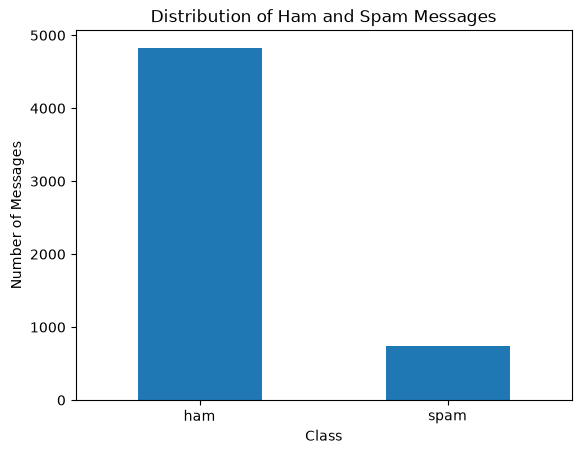

In [25]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4825.0   71.023627  58.016023   2.0   33.0   52.0   92.0  910.0
spam    747.0  138.866131  29.183082  13.0  132.5  149.0  157.0  224.0


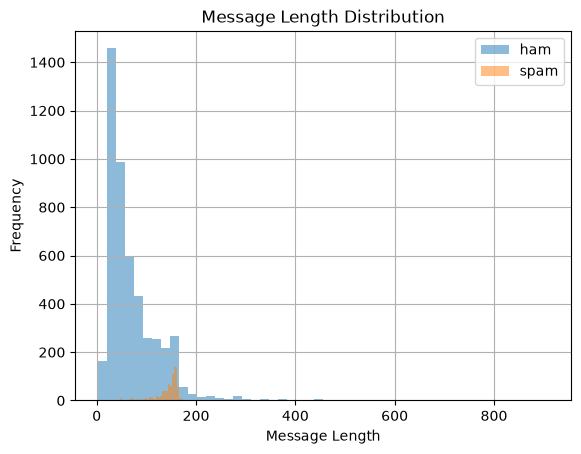

In [26]:
df["text_length"] = df["text"].str.len()

print(df.groupby("label")["text_length"].describe())

df[df["label"] == "ham"]["text_length"].hist(
    bins=50,
    alpha=0.5,
    label="ham"
)

df[df["label"] == "spam"]["text_length"].hist(
    bins=50,
    alpha=0.5,
    label="spam"
)

plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [27]:
df.groupby("label")["text_length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4825.0,71.023627,58.016023,2.0,33.0,52.0,92.0,910.0
spam,747.0,138.866131,29.183082,13.0,132.5,149.0,157.0,224.0


In [28]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/tetianareshetnik/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [29]:
import re

def clean_text(text):
    # lowercase
    text = text.lower()

    # remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # keep only letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # remove stop words
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [30]:
df["clean_text"] = df["text"].apply(clean_text)

df[["text", "clean_text"]].head()

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though


In [31]:
df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df[["label", "target"]].head()

,label,target
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0


In [32]:
# train/val/test split
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    df["clean_text"],
    df["target"],
    test_size=0.2,
    random_state=42,
    stratify=df["target"]
)

print("Train size:", len(X_train))
print("Validation size:", len(X_val))

print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

Train size: 4457
Validation size: 1115

Train distribution:
target
0    0.865829
1    0.134171
Name: proportion, dtype: float64

Validation distribution:
target
0    0.866368
1    0.133632
Name: proportion, dtype: float64


In [33]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)

print("Train BoW shape:", X_train_bow.shape)
print("Validation BoW shape:", X_val_bow.shape)


Train BoW shape: (4457, 5000)
Validation BoW shape: (1115, 5000)


In [34]:
# logistic regression model

from sklearn.linear_model import LogisticRegression

bow_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

bow_model.fit(X_train_bow, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [36]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predictions
y_pred_bow = bow_model.predict(X_val_bow)

# Probability of spam class (1)
y_prob_bow = bow_model.predict_proba(X_val_bow)[:, 1]

print(y_pred_bow[:10])
print(y_prob_bow[:10])

bow_accuracy = accuracy_score(y_val, y_pred_bow)
bow_auc = roc_auc_score(y_val, y_prob_bow)

print(f"BoW Accuracy: {bow_accuracy:.4f}")
print(f"BoW ROC-AUC: {bow_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred_bow,
    target_names=["ham", "spam"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_bow))

[0 0 0 1 0 0 0 0 0 0]
[0.00138117 0.04734155 0.00735801 0.92767276 0.00110845 0.00667805
 0.01851642 0.0125641  0.01381529 0.00743569]
BoW Accuracy: 0.9812
BoW ROC-AUC: 0.9874

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       1.00      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.99      0.93      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Confusion Matrix:
[[966   0]
 [ 21 128]]


In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)

print("Train TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)

Train TF-IDF shape: (4457, 5000)
Validation TF-IDF shape: (1115, 5000)


In [ ]:
# навчання моделі 
tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

tfidf_model.fit(X_train_tfidf, y_train)


y_pred_tfidf = tfidf_model.predict(X_val_tfidf)
y_prob_tfidf = tfidf_model.predict_proba(X_val_tfidf)[:, 1]

tfidf_accuracy = accuracy_score(y_val, y_pred_tfidf)
tfidf_auc = roc_auc_score(y_val, y_prob_tfidf)

print(f"TF-IDF Accuracy: {tfidf_accuracy:.4f}")
print(f"TF-IDF ROC-AUC: {tfidf_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred_tfidf,
    target_names=["ham", "spam"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_tfidf))



TF-IDF Accuracy: 0.9668
TF-IDF ROC-AUC: 0.9869

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       0.98      0.77      0.86       149

    accuracy                           0.97      1115
   macro avg       0.97      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115


Confusion Matrix:
[[964   2]
 [ 35 114]]


In [41]:
import numpy as np

glove_path = "data/glove.6B.100d.txt"

embeddings_index = {}

with open(glove_path, encoding="utf-8") as f:
    for line in f:
        values = line.split()

        word = values[0]
        vector = np.asarray(values[1:], dtype="float32")

        embeddings_index[word] = vector

print("Loaded word vectors:", len(embeddings_index))
print("Vector size:", len(embeddings_index["hello"]))

print(embeddings_index["free"][:10])

Loaded word vectors: 400000
Vector size: 100
[ 0.16057   0.1303    0.07715  -0.69427   0.49514   0.46282   0.31438
 -0.010989 -0.18431  -0.27871 ]


In [42]:
EMBEDDING_DIM = 100

def text_to_embedding(text):
    words = text.split()

    vectors = [
        embeddings_index[word]
        for word in words
        if word in embeddings_index
    ]

    if len(vectors) == 0:
        return np.zeros(EMBEDDING_DIM)

    return np.mean(vectors, axis=0)


X_train_glove = np.vstack([
    text_to_embedding(text)
    for text in X_train
])

X_val_glove = np.vstack([
    text_to_embedding(text)
    for text in X_val
])

print("Train GloVe shape:", X_train_glove.shape)
print("Validation GloVe shape:", X_val_glove.shape)

Train GloVe shape: (4457, 100)
Validation GloVe shape: (1115, 100)


In [43]:
glove_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

glove_model.fit(X_train_glove, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [44]:
y_pred_glove = glove_model.predict(X_val_glove)
y_prob_glove = glove_model.predict_proba(X_val_glove)[:, 1]

In [45]:
glove_accuracy = accuracy_score(y_val, y_pred_glove)
glove_auc = roc_auc_score(y_val, y_prob_glove)

print(f"GloVe Accuracy: {glove_accuracy:.4f}")
print(f"GloVe ROC-AUC: {glove_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred_glove,
    target_names=["ham", "spam"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_glove))

GloVe Accuracy: 0.9399
GloVe ROC-AUC: 0.9617

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      0.98      0.97       966
        spam       0.82      0.71      0.76       149

    accuracy                           0.94      1115
   macro avg       0.89      0.84      0.86      1115
weighted avg       0.94      0.94      0.94      1115


Confusion Matrix:
[[942  24]
 [ 43 106]]


In [46]:
results = pd.DataFrame({
    "Model": [
        "BoW + Logistic Regression",
        "TF-IDF + Logistic Regression",
        "GloVe + Logistic Regression"
    ],
    "Accuracy": [
        bow_accuracy,
        tfidf_accuracy,
        glove_accuracy
    ],
    "ROC-AUC": [
        bow_auc,
        tfidf_auc,
        glove_auc
    ]
})

results

,Model,Accuracy,ROC-AUC
0,BoW + Logistic Regression,0.981166,0.987414
1,TF-IDF + Logistic Regression,0.966816,0.986886
2,GloVe + Logistic Regression,0.939910,0.961701


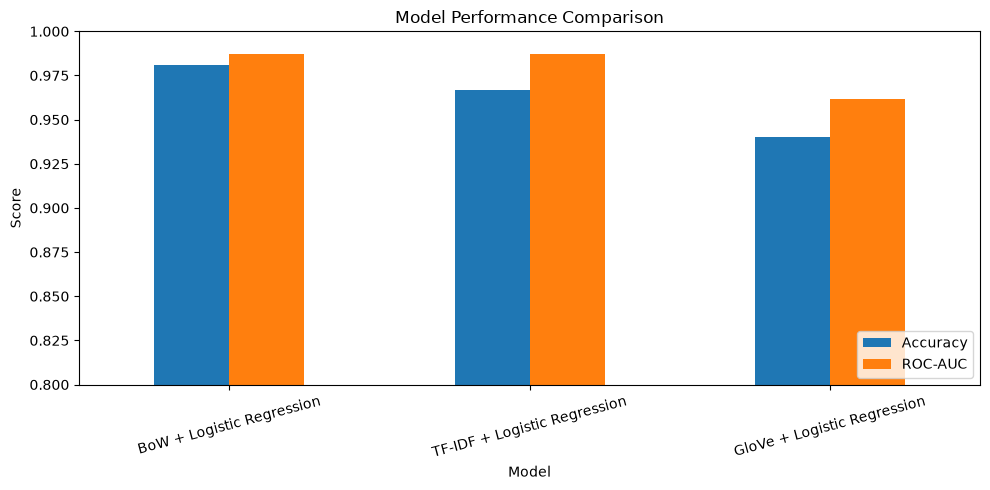

In [47]:
results.set_index("Model")[["Accuracy", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0.8, 1.0)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [48]:
y_train_pred_bow = bow_model.predict(X_train_bow)
y_train_prob_bow = bow_model.predict_proba(X_train_bow)[:, 1]

train_accuracy_bow = accuracy_score(y_train, y_train_pred_bow)
train_auc_bow = roc_auc_score(y_train, y_train_prob_bow)

print(f"Train Accuracy:      {train_accuracy_bow:.4f}")
print(f"Validation Accuracy: {bow_accuracy:.4f}")

print(f"\nTrain ROC-AUC:       {train_auc_bow:.4f}")
print(f"Validation ROC-AUC:  {bow_auc:.4f}")

Train Accuracy:      0.9946
Validation Accuracy: 0.9812

Train ROC-AUC:       0.9998
Validation ROC-AUC:  0.9874


### Висновок
У межах роботи було розв’язано задачу бінарної класифікації текстових повідомлень на ham та spam. Під час попереднього аналізу було виявлено дисбаланс класів: приблизно 87% повідомлень належать до класу ham і 13% — до spam. Також spam-повідомлення в середньому виявилися довшими: близько 139 символів проти 71 символу для ham.

Для представлення текстових даних було досліджено три підходи: Bag of Words (BoW), TF-IDF та попередньо навчені GloVe embeddings. Для коректного порівняння для всіх трьох представлень використовувалась модель Logistic Regression.

Найкращий результат показала модель BoW + Logistic Regression: Accuracy становила 98.12%, а ROC-AUC — 0.9874. Для класу spam модель отримала precision 1.00, recall 0.86 та F1-score 0.92. Із 149 spam-повідомлень модель правильно визначила 128 та пропустила 21.

Модель TF-IDF + Logistic Regression отримала Accuracy 96.68% та ROC-AUC 0.9869. ROC-AUC практично не відрізняється від BoW, проте recall для spam зменшився до 0.77, тому модель пропустила більше небажаних повідомлень.

Модель GloVe + Logistic Regression показала Accuracy 93.99% та ROC-AUC 0.9617. Recall для spam становив 0.71. Нижчий результат можна пояснити використанням усередненого вектора embeddings слів повідомлення. Такий підхід враховує семантичну інформацію про слова, але частково втрачає інформацію про їх частоту, порядок та наявність конкретних ключових фраз, які є важливими для визначення spam.

Оскільки набір даних є незбалансованим, Accuracy недостатньо для повної оцінки моделей. Тому додатково було використано ROC-AUC, precision, recall та F1-score. Особливо важливим для задачі фільтрації spam є recall класу spam, оскільки він показує, яку частку небажаних повідомлень модель здатна виявити.

Для найкращої BoW-моделі також було перевірено можливе перенавчання. Accuracy на навчальній вибірці становила 99.46%, а на валідаційній — 98.12%. ROC-AUC становив відповідно 0.9998 та 0.9874. Різниця між навчальною та валідаційною вибірками є невеликою, тому результати не вказують на критичне перенавчання моделі.

Таким чином, для даного набору даних найкращим підходом виявився Bag of Words у поєднанні з Logistic Regression, оскільки він продемонстрував найвищу загальну якість класифікації та найкраще виявляв spam серед трьох досліджених підходів.